<h1 style="
text-align:center;
color:#1565C0;">
💧 Water Potability Prediction
</h1>

<h3 style="
text-align:center;
color:#546E7A;">
Machine Learning Based Water Quality Assessment
</h3>

<hr>

<div style="
background-color:#E3F2FD;
color : #000000;
padding:15px;
border-radius:10px;">

<h3>🎯 Objective</h3>

Develop a machine learning model capable of predicting whether water is potable based on various water quality parameters.

</div>

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score ,f1_score , precision_score , recall_score , classification_report ,confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV ,RandomizedSearchCV
from sklearn.metrics import roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
import joblib # For model saving


sns.set_theme(style="whitegrid", context="notebook") #For graphs


<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📂 Dataset Loading
</h2>

In [7]:
df = pd.read_csv('water_potability.csv')

In [8]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


<div style="
background-color:#E3F2FD;
padding:15px;
border-radius:10px;
color:#1B5E20;
border-left:6px solid #2E7D32;">

<h3>📋 About the Dataset</h3>

**Source:** Was provided with the project requirements<br>
**Shape:** 3276 rows × 10 columns (9 features + 1 target)<br><br>

| Feature | Description |
|---|---|
| **ph** | pH value of water (0–14 scale) |
| **Hardness** | Capacity of water to precipitate soap (mg/L) |
| **Solids** | Total dissolved solids in water (ppm) |
| **Chloramines** | Amount of chloramines (ppm) |
| **Sulfate** | Amount of sulfates dissolved (mg/L) |
| **Conductivity** | Electrical conductivity of water (μS/cm) |
| **Organic_carbon** | Amount of organic carbon (ppm) |
| **Trihalomethanes** | Amount of trihalomethanes (μg/L) |
| **Turbidity** | Measure of light-emitting properties (NTU) |
| **Potability** | Target — 1 = Potable, 0 = Not Potable |

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📋 Dataset Overview
</h2>

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

The dataset contains 3276 observations and 10 variables, including the target variable Potability.
All features are of <b>float64</b> type except the target <b>Potability</b> (int64) — no categorical encoding is needed, which simplifies preprocessing.
</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📊 Statistical Summary
</h2>

In [10]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Features exhibit significantly different scales and ranges — for example, <b>Solids</b> reaches up to ~61000 ppm while <b>Turbidity</b> has a maximum of only ~7 NTU. This large variation in magnitude confirms the need for feature scaling before model training.
</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
❓ Missing Value Analysis
</h2>

In [11]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Missing values were identified in:

<ul>
<li>pH</li>
<li>Sulfate</li>
<li>Trihalomethanes</li>
</ul>

These values will be handled during preprocessing.</div>

In [12]:
df.duplicated().sum()

np.int64(0)

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

No duplicate rows were found in the dataset. The dataset is clean in terms of duplicate entries.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🎯 Target Variable Analysis
</h2>

In [13]:
df.Potability.value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

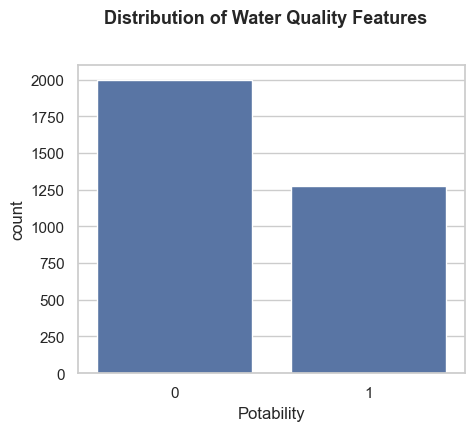

In [59]:
plt.figure(figsize=(5,4))

sns.countplot(x = 'Potability' , data = df)
plt.suptitle(
    'Distribution of Water Quality Features',
    fontsize=13,
    fontweight='bold',
    y=1.02
)
plt.savefig('Target Variable Analysis.png',bbox_inches='tight')

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

The dataset shows moderate class imbalance — <b>1998 samples (61%)</b> are non-potable and <b>1278 samples (39%)</b> are potable. Training on this imbalanced data as-is would bias the model toward predicting non-potable. This will be addressed using SMOTE after the train-test split.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📈 Exploratory Data Analysis
</h2>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;">

<b>Step 1 — Distribution of all features</b><br>
Histograms with KDE curves to understand the shape and spread of each feature.

</div>

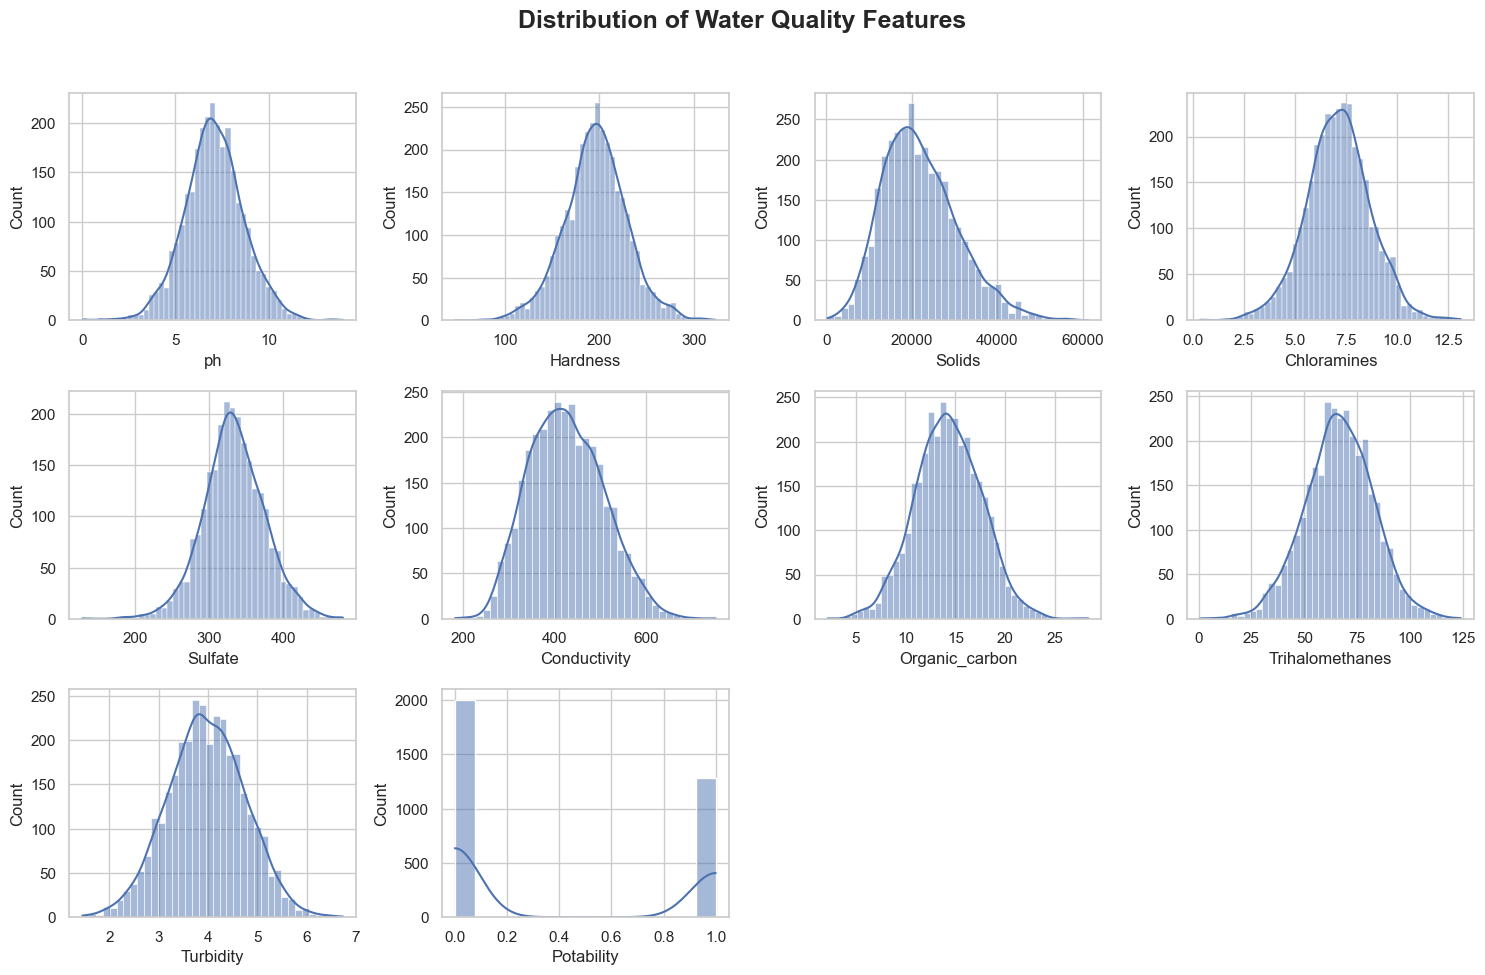

In [15]:

plt.figure(figsize=(15,12))
columns = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity','Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

for i,col  in enumerate(columns,1):

    plt.subplot(4,4,i)
    sns.histplot(df[col] , kde = True)


# Main title for the entire figure
plt.suptitle(
    'Distribution of Water Quality Features',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.savefig('Distribution of Water Quality Features.png', bbox_inches='tight')
plt.show()


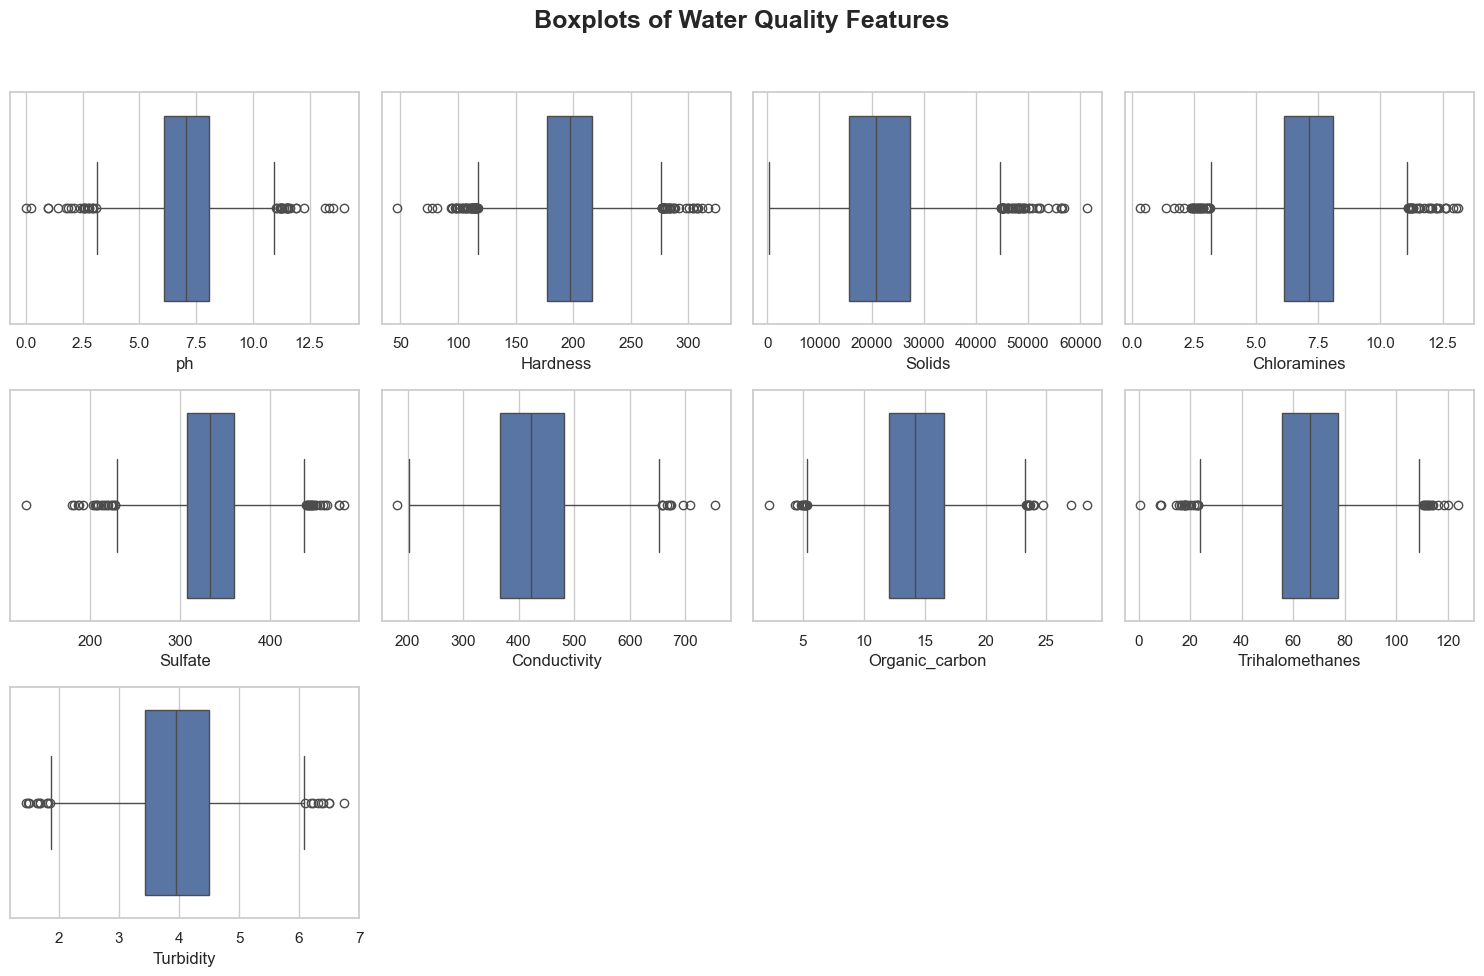

In [16]:
plt.figure(figsize=(15,12))
columns = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity','Organic_carbon', 'Trihalomethanes', 'Turbidity']
for i,col  in enumerate(columns,1):
    plt.subplot(4,4,i)
    sns.boxplot(x= df[col] )
    plt.tight_layout()

# Main title for the entire figure
plt.suptitle(
    "Boxplots of Water Quality Features",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.savefig('Boxplots of Water Quality Features.png', bbox_inches='tight')
plt.show()

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Most features are approximately normally distributed. <b>Solids</b> and <b>Hardness</b> show the most notable outliers based on the boxplots. These outliers were intentionally retained as they likely represent genuine extreme water quality measurements rather than data entry errors — removing them could reduce real-world model applicability.

</div>

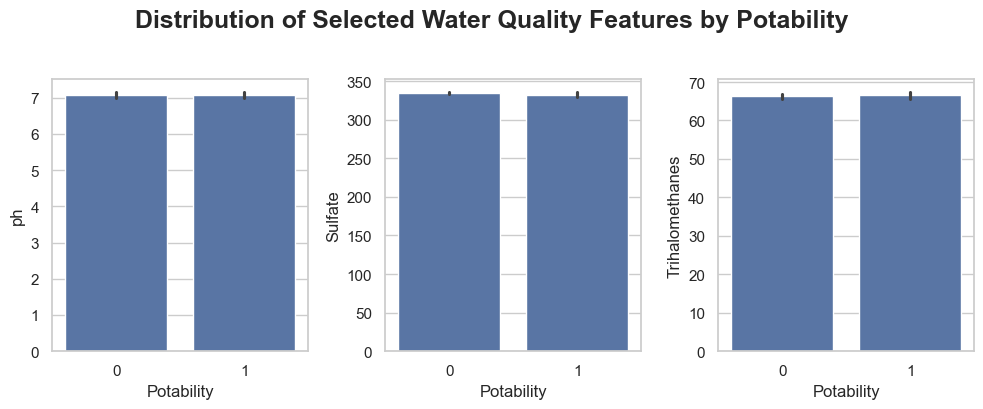

In [17]:
plt.figure(figsize=(10,4))
columns = ['ph','Sulfate','Trihalomethanes']
for i,col  in enumerate(columns,1):
    plt.subplot(1,3,i)
    sns.barplot(
    x='Potability',
    y=col,
    data=df
)

# Main title for the entire figure
plt.suptitle(
    "Distribution of Selected Water Quality Features by Potability",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.savefig('Distribution of Selected Water Quality Features by Potability.png', bbox_inches='tight')


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

pH and Sulfate show slight mean differences between potable and non-potable samples, but the overlap between the two classes is large. This suggests these features alone are weak individual predictors — the model will need to rely on combinations of features rather than any single variable.

</div>

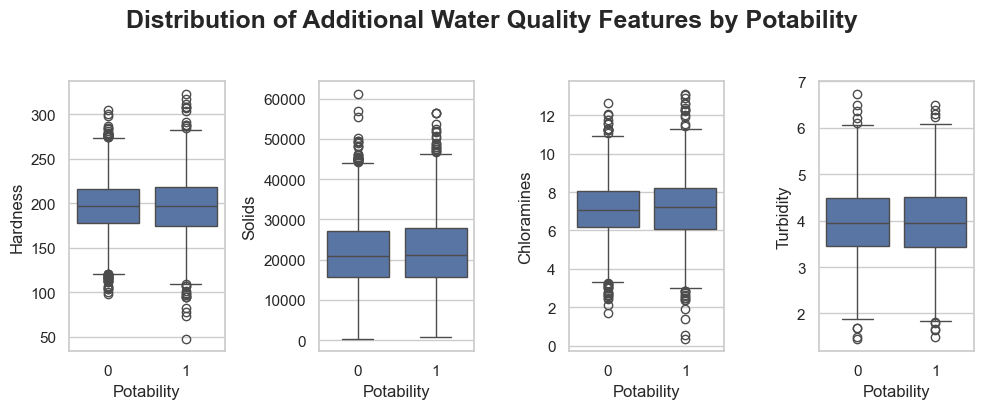

In [18]:
plt.figure(figsize=(10,4))
columns = [ 'Hardness', 'Solids', 'Chloramines','Turbidity']
for i,col  in enumerate(columns,1):
    plt.subplot(1,4,i)
    sns.boxplot(x= df.Potability , y = df[col])



# Main title for the entire figure
plt.suptitle(
    "Distribution of Additional Water Quality Features by Potability",
    fontsize=18,
    fontweight="bold",
    y=1.02
)


plt.tight_layout()
plt.savefig('Distribution of Additional Water Quality Features by Potability.png', bbox_inches='tight')

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Hardness, Solids, Chloramines, and Turbidity show minimal separation between potable and non-potable classes. No single feature cleanly separates the two — reinforcing that this is a multi-feature classification problem requiring ensemble or non-linear models.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🔥 Correlation Analysis
</h2>

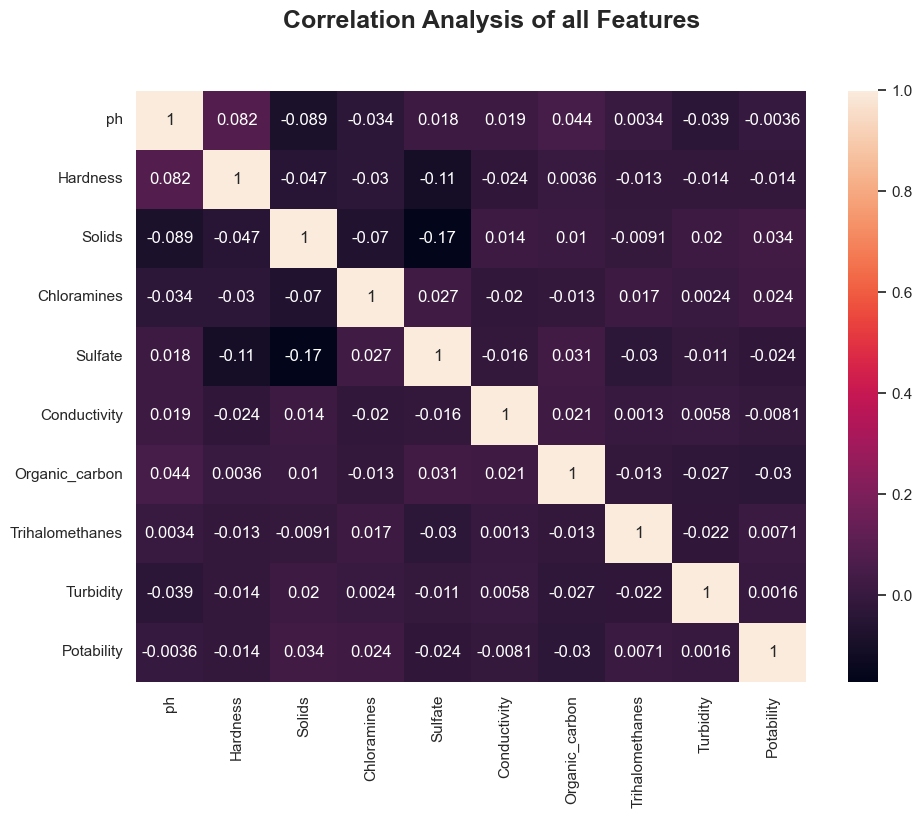

In [19]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr() , annot= True)


# Main title for the entire figure
plt.suptitle(
    "Correlation Analysis of all Features",
    fontsize=18,
    fontweight="bold",
    y=1.02
)


plt.tight_layout()
plt.savefig('Correlation Analysis of all Features.png', bbox_inches='tight')

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

No feature shows strong correlation with Potability — all values are below 0.1 in magnitude. There is also no significant multicollinearity between features. This weak linear signal suggests that tree-based models capable of capturing non-linear interactions (Random Forest, XGBoost) are likely to outperform linear approaches.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
⚙️ Data Preprocessing
</h2>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;">

<b>Handling Missing Values</b><br>
Three features contain missing values: <b>ph</b> (491 nulls), <b>Sulfate</b> (781 nulls), and <b>Trihalomethanes</b> (162 nulls). Before deciding on an imputation strategy, skewness is checked — if a feature is approximately symmetric (low skew), mean imputation is appropriate; otherwise median would be preferred.

</div>

In [20]:
df[['ph','Sulfate','Trihalomethanes']].skew()

ph                 0.025630
Sulfate           -0.035947
Trihalomethanes   -0.083031
dtype: float64

In [21]:
df.ph.fillna(df.ph.mean() , inplace= True)
df.Trihalomethanes.fillna(df.Trihalomethanes.mean() , inplace= True)
df.Sulfate.fillna(df.Sulfate.mean() , inplace= True)

In [22]:
df.isna().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

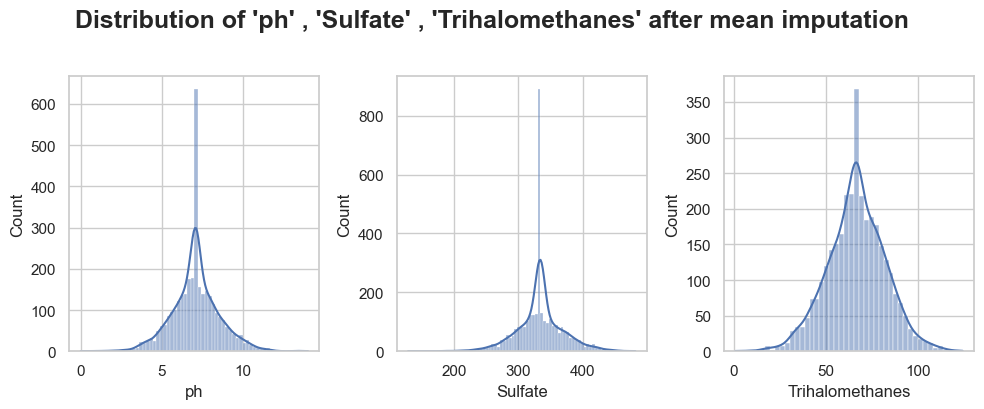

In [23]:
plt.figure(figsize=(10,4))
columns_after_filling = ['ph','Sulfate', 'Trihalomethanes']
for i,col  in enumerate(columns_after_filling,1):
    plt.subplot(1,3,i)
    sns.histplot(df[col] , kde = True)

# Main title for the entire figure
plt.suptitle(
    "Distribution of 'ph' , 'Sulfate' , 'Trihalomethanes' after mean imputation",
    fontsize=18,
    fontweight="bold",
    y=1.02
)


plt.tight_layout()
plt.savefig("Distribution of 'ph' , 'Sulfate' , 'Trihalomethanes' after mean imputation.png", bbox_inches='tight')

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Distributions of ph, Sulfate, and Trihalomethanes remain approximately unchanged after mean imputation, confirming that the imputation strategy did not distort the underlying data distribution.

</div>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;">

<b>Feature and Target Separation</b><br>
Separating the feature matrix X (all columns except Potability) from the target variable y before proceeding to train-test split.

</div>

In [24]:
X = df.drop('Potability' , axis = 1)
y = df.Potability

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
✂️ Train-Test Split
</h2>

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X , y  , test_size= 0.2 , random_state= 42 , stratify= y)

In [26]:
y_train.value_counts(normalize=True)


Potability
0    0.609924
1    0.390076
Name: proportion, dtype: float64

In [27]:
y_test.value_counts(normalize=True)


Potability
0    0.609756
1    0.390244
Name: proportion, dtype: float64

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

The stratified split successfully preserved the original class ratio in both sets — approximately <b>61% non-potable and 39% potable</b>. This ensures the test set is a fair, representative sample of the real distribution and that evaluation metrics are not distorted by an accidentally skewed split.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
⚖️ Handling Class Imbalance Using SMOTE
</h2>

<div style="
background-color:#FFF8E1;
padding:15px;
border-left:6px solid #F9A825;
border-radius:8px;
color:#E65100;
font-size:15px;
line-height:1.6;">

<b>⚠️ Important — Why SMOTE is applied after splitting</b><br><br>

SMOTE is applied <b>only on the training set</b> and never on the test set. If SMOTE were applied before the train-test split, synthetic samples derived from the test data would leak into training — causing the model to appear more accurate than it actually is. By applying SMOTE after splitting, the test set remains a true holdout of real, unseen data.

</div>

In [28]:


smote = SMOTE(random_state=42)

X_train_smote , y_train_smote = smote.fit_resample(X_train , y_train)

In [29]:
X_train_smote.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               3196 non-null   float64
 1   Hardness         3196 non-null   float64
 2   Solids           3196 non-null   float64
 3   Chloramines      3196 non-null   float64
 4   Sulfate          3196 non-null   float64
 5   Conductivity     3196 non-null   float64
 6   Organic_carbon   3196 non-null   float64
 7   Trihalomethanes  3196 non-null   float64
 8   Turbidity        3196 non-null   float64
dtypes: float64(9)
memory usage: 224.8 KB


In [30]:
y_train_smote.value_counts()
# Handled class imbalances

Potability
0    1598
1    1598
Name: count, dtype: int64

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

After SMOTE, the training set is perfectly balanced — both classes now have equal representation. The test set remains untouched with its original 61/39 distribution to ensure realistic evaluation.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📏 Feature Scaling
</h2>

In [31]:
# Scaling as values are vastly spreaded
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

StandardScaler is fit <b>only on the training data</b> and then applied to the test data — ensuring no information from the test set influences the scaling parameters. This prevents a subtle but common form of data leakage.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🤖 Model Training
</h2>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;
line-height:1.6;">

<b>Baseline Model Comparison</b><br>
Five classifiers are trained with default parameters to establish a performance baseline: KNN, Decision Tree, SVM, Random Forest, and XGBoost. This helps identify which model families are best suited to this problem before hyperparameter tuning.

</div>

In [32]:
base_model_pipeline  = {
    'KNN'            : KNeighborsClassifier(),
    'Decision Tree'  : DecisionTreeClassifier(random_state=42),
    'SVM'            : SVC(),
    'Random Forest'  : RandomForestClassifier(random_state=42 , class_weight='balanced'),
    'XGBoost'        : XGBClassifier(random_state = 42 , eval_metric = 'logloss',)
}

result = []

for name,model in base_model_pipeline.items():
    model.fit(X_train_scaled , y_train_smote)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test , y_pred)
    f1 = f1_score(y_test , y_pred)
    
    result.append({
        'Model'    : name,
        'Accuracy' : acc,
        'f1 score' : f1
    })

pd.DataFrame(result).sort_values(
    by='Accuracy',
    ascending=False
)

,Model,Accuracy,f1 score
3,Random Forest,0.650915,0.509636
4,XGBoost,0.632622,0.526523
2,SVM,0.603659,0.527273
0,KNN,0.579268,0.496350
1,Decision Tree,0.547256,0.464865


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

On the held-out test set, <b>Random Forest</b> and <b>XGBoost</b> lead on both Accuracy and F1 Score, with <b>SVM</b> performing competitively as well. <b>KNN</b> and <b>Decision Tree</b> trail behind — Decision Tree likely overfits on a single split while KNN struggles with the high-dimensional, noisy feature space of this dataset. These baseline results guide the selection of the top 3 models to carry forward into cross-validation.

</div>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;
line-height:1.6;">

<b>Cross-Validation</b><br>
A single train/test split can produce results influenced by how data happened to be divided. 5-fold cross-validation gives a more stable and reliable performance estimate by averaging results across 5 different splits of the training data.

</div>

In [33]:
cv_models = {
    'KNN'            : KNeighborsClassifier(),
    'Decision Tree'  : DecisionTreeClassifier(random_state=42),
    'SVM'            : SVC(),
    'Random Forest'  : RandomForestClassifier(random_state=42, class_weight='balanced'),
    'XGBoost'        : XGBClassifier(random_state = 42 , eval_metric = 'logloss')
}
cv_model_scores = []
for name,model in cv_models.items():
    scores = cross_val_score(
        model , 
        X_train_scaled,
        y_train_smote,
        cv= 5 ,
        scoring= 'accuracy'
    )
    cv_model_scores.append({
        'Name' : name,
        'CV_score_mean' : scores.mean()
    })

cv_model_scores

pd.DataFrame(cv_model_scores).sort_values(
    by='CV_score_mean',
    ascending=False)

,Name,CV_score_mean
3,Random Forest,0.697436
4,XGBoost,0.676785
2,SVM,0.666458
0,KNN,0.643624
1,Decision Tree,0.602932


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Cross-validation scores are consistent with the baseline test results — <b>Random Forest</b>, <b>XGBoost</b>, and <b>SVM</b> are the top 3 performers across all 5 folds. Their higher and more stable mean CV scores confirm they generalise better than KNN and Decision Tree. These three models will be taken into hyperparameter tuning.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🎛️ Hyperparameter Tuning
</h2>

<div style="
background-color:#E3F2FD;
padding:12px 15px;
border-radius:8px;
color:#1565C0;
font-size:15px;
line-height:1.6;">

<b>Hyperparameter Tuning Strategy</b><br>
<b>GridSearchCV</b> is used for Random Forest and SVM — their search spaces are small enough for exhaustive search. <b>RandomizedSearchCV</b> is used for XGBoost as its larger hyperparameter space makes exhaustive search computationally expensive; random sampling finds good parameters much faster.

</div>

In [34]:
rf = RandomForestClassifier(random_state=42,class_weight= 'balanced')
svm = SVC()
xgboost = XGBClassifier(random_state = 42 , eval_metric = 'logloss')

rf_param_grid = {
    'n_estimators':[100,200,300],
    'max_depth':[10,20,None],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4]
}

svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}

xgb_param_rand = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

rf_grid_clf = GridSearchCV(estimator= rf , 
                           param_grid= rf_param_grid ,
                           cv = 5 ,
                           n_jobs= -1, #use all cpu cores
                           return_train_score= False)
rf_grid_clf.fit(X_train_scaled , y_train_smote)


svm_grid_clf = GridSearchCV(
    estimator=svm,
    param_grid=svm_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid_clf.fit(X_train_scaled , y_train_smote)


xgb_random_clf = RandomizedSearchCV(
    estimator=xgboost,
    param_distributions=xgb_param_rand,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
xgb_random_clf.fit(X_train_scaled , y_train_smote)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used h

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🎯 Tuning Results — Best Parameters & CV Scores
</h2>

In [35]:
cv_results = pd.DataFrame({
    'Model': ['Random Forest', 'SVM', 'XGBoost'],
    'Best CV Accuracy': [
        rf_grid_clf.best_score_,
        svm_grid_clf.best_score_,
        xgb_random_clf.best_score_
    ],
    'Best Parameters': [
        str(rf_grid_clf.best_params_),
        str(svm_grid_clf.best_params_),
        str(xgb_random_clf.best_params_)
    ]
})

cv_results.sort_values(
    by='Best CV Accuracy',
    ascending=False
)

,Model,Best CV Accuracy,Best Parameters
0,Random Forest,0.702442,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."
2,XGBoost,0.694932,"{'subsample': 0.8, 'n_estimators': 300, 'max_d..."
1,SVM,0.680230,"{'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}"


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

After exhaustive/randomized search, <b>Random Forest</b> achieved the highest cross-validation accuracy among the three tuned models. The best parameters found reflect a deeper, more complex forest than the default — higher <code>n_estimators</code> and controlled <code>max_depth</code> help reduce variance without overfitting. All three best estimators are now extracted and will be evaluated on the unseen test set.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🏆 Final Model Evaluation
</h2>

In [36]:
# best models
best_rf = rf_grid_clf.best_estimator_
best_svm = svm_grid_clf.best_estimator_
best_xgb = xgb_random_clf.best_estimator_

In [37]:
#y predictions
rf_y_pred = best_rf.predict(X_test_scaled)
svm_y_pred = best_svm.predict(X_test_scaled)
xgb_y_pred = best_xgb.predict(X_test_scaled)

In [38]:
comparison = []

y_pred_models = {
    'Random Forest' : rf_y_pred,
    'SVM'           : svm_y_pred,
    'XGBoost'       : xgb_y_pred
}

for name , pred in y_pred_models.items():
    comparison.append({
        'Model' : name,
        'Accuracy' : accuracy_score(y_test ,pred),
        'Precision' : precision_score(y_test,pred),
        'Recall' : recall_score(y_test,pred),
        'F1 Score' : f1_score(y_test,pred)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.sort_values(
    by='F1 Score',
    ascending=False
)


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.652439,0.564815,0.476562,0.516949
2,XGBoost,0.626524,0.523207,0.484375,0.503043
1,SVM,0.577744,0.463918,0.527344,0.493601


<div style="
background-color:#E8F5E9;
padding:18px;
border-left:8px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.8;">

<h3 style="margin-top:0; color:#1B5E20;">✅ Final Model Selected — Random Forest</h3>

After evaluating all three tuned models on the held-out test set, <b>Random Forest</b> achieved the <b>highest Accuracy and F1 Score</b> and is selected as the final model for deployment.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📉 Confusion Matrix
</h2>

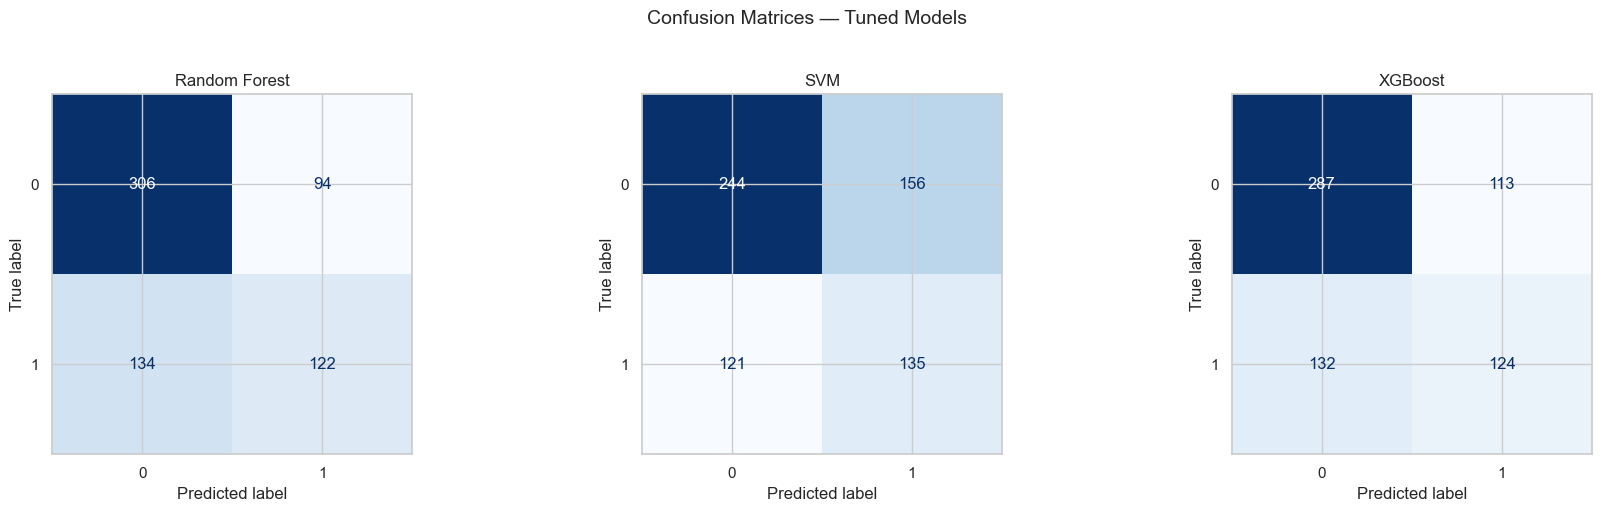

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_preds = {
    'Random Forest': rf_y_pred,
    'SVM'          : svm_y_pred,
    'XGBoost'      : xgb_y_pred
}

for ax, (name, pred) in zip(axes, models_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        ax=ax,
        cmap='Blues',
        colorbar=False
    )
    ax.set_title(name)

plt.suptitle('Confusion Matrices — Tuned Models', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight')
plt.show()

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Across all three models, <b>False Negatives</b> (predicting water as potable when it is not) are the most critical error in this domain — consuming unsafe water classified as safe is far more dangerous than discarding safe water. <b>Random Forest</b> achieves the best balance between minimising false negatives and false positives. SVM tends to predict the majority class more aggressively, resulting in more false negatives on the potable class.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
📈 ROC Curve & AUC Score
</h2>

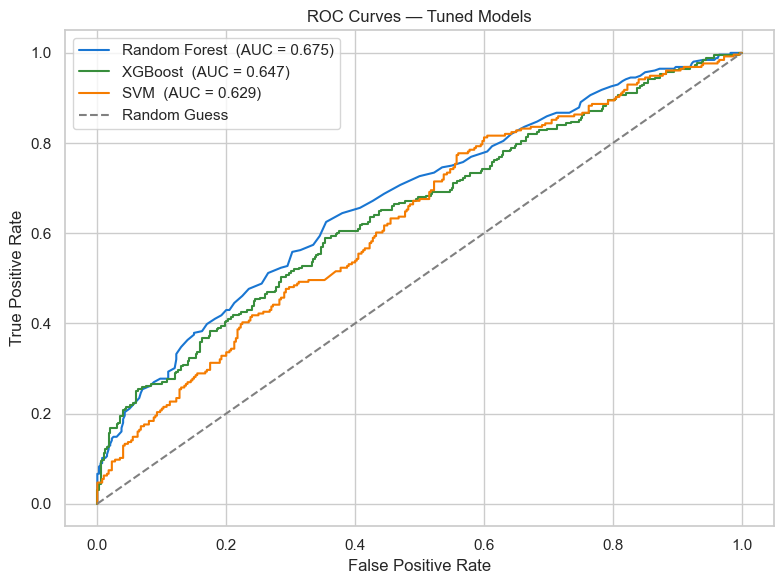

In [40]:

# SVM needs probability=True — re-fit best SVM with it enabled
from sklearn.svm import SVC
best_svm_prob = SVC(probability=True, **svm_grid_clf.best_params_)
best_svm_prob.fit(X_train_scaled, y_train_smote)

# Get probabilities
rf_prob  = best_rf.predict_proba(X_test_scaled)[:, 1]
xgb_prob = best_xgb.predict_proba(X_test_scaled)[:, 1]
svm_prob = best_svm_prob.predict_proba(X_test_scaled)[:, 1]

# AUC scores
rf_auc  = roc_auc_score(y_test, rf_prob)
xgb_auc = roc_auc_score(y_test, xgb_prob)
svm_auc = roc_auc_score(y_test, svm_prob)

# Plot all 3 on same figure
plt.figure(figsize=(8, 6))

for prob, auc, name, color in [
    (rf_prob,  rf_auc,  'Random Forest', '#1976D2'),
    (xgb_prob, xgb_auc, 'XGBoost',       '#388E3C'),
    (svm_prob, svm_auc, 'SVM',            '#F57C00')
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name}  (AUC = {auc:.3f})', color=color)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Tuned Models')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curves.png', bbox_inches='tight')
plt.show()

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

All three models achieve AUC scores in the <b>0.65–0.70 range</b>, confirming moderate discriminative ability. <b>Random Forest</b> leads with the highest AUC, meaning it has the best overall ability to rank potable samples above non-potable ones across all classification thresholds. An AUC of ~0.67 is consistent with published benchmarks on this dataset and reflects the inherently weak feature-target signal rather than a modelling failure.

</div>

<h2 style="
background-color:#1976D2;
color:white;
padding:12px;
border-radius:10px;">
🌟 Feature Importance Analysis
</h2>

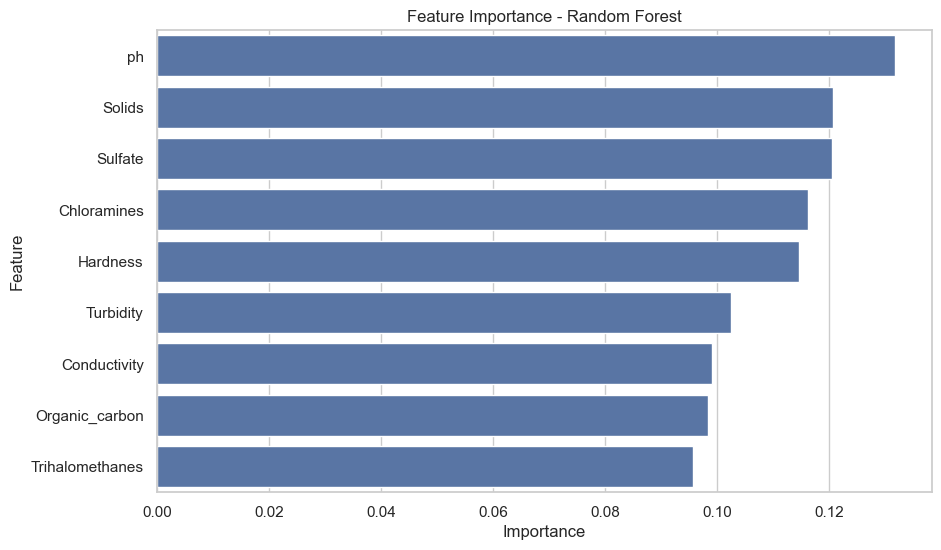

In [41]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.savefig('Feature_importance - Random Forest.png', bbox_inches='tight')
plt.show()

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

<b>Solids</b>, <b>Sulfate</b>, and <b>pH</b> are the three most important features according to Random Forest's feature importances. Interestingly, despite having low individual correlation with Potability (as seen in the heatmap), these features carry the most predictive signal when used in combination inside tree splits. Features like <b>Conductivity</b> and <b>Turbidity</b> contribute the least — their distributions were nearly identical across potable and non-potable classes.

</div>

In [42]:

joblib.dump(best_rf, 'water_potability_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Two artifacts are saved: the <b>trained Random Forest model</b> (<code>water_potability_model.pkl</code>) and the <b>StandardScaler</b> (<code>scaler.pkl</code>) used during training. It is critical to save the scaler alongside the model — any new input at inference time must be scaled using the <i>same parameters</i> (mean and standard deviation) that were computed on the training data. Using a freshly fitted scaler on new data would produce incorrect predictions.

</div>

<h2 style="
background-color:#455A64;
color:white;
padding:12px;
border-radius:10px;">
🧪 Additional Experiments
</h2>

<div style="
background-color:#ECEFF1;
padding:15px;
border-left:6px solid #455A64;
border-radius:8px;
color:#263238;">

<b>Purpose</b><br><br>

Additional experiments were conducted to investigate whether alternative preprocessing techniques could improve prediction performance.

</div>

In [43]:

# models without smote
scaler2 = StandardScaler()
X_train_2 = scaler2.fit_transform(X_train)



In [44]:
base_model_pipeline  = {
    'KNN'            : KNeighborsClassifier(),
    'Decision Tree'  : DecisionTreeClassifier(random_state=42),
    'SVM'            : SVC(),
    'Random Forest'  : RandomForestClassifier(random_state=42 , class_weight= 'balanced'),
    'XGBoost'        : XGBClassifier(random_state = 42 , eval_metric = 'logloss')
}

result = []

for name,model in base_model_pipeline.items():
    model.fit(X_train_2 , y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test , y_pred)
    f1 = f1_score(y_test , y_pred)
    
    result.append({
        'Model'    : name,
        'Accuracy' : acc,
        'f1 score' : f1
    })


pd.DataFrame(result).sort_values(
    by='Accuracy',
    ascending=False
)

,Model,Accuracy,f1 score
2,SVM,0.669207,0.388732
3,Random Forest,0.660061,0.389041
4,XGBoost,0.615854,0.422018
0,KNN,0.612805,0.386473
1,Decision Tree,0.594512,0.463710


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Without SMOTE, baseline accuracy appears similar on the surface, but F1 scores are noticeably lower — particularly for the potable class. The model is predicting non-potable more often due to the raw class imbalance in the training data.

</div>

In [45]:
models = {
    'KNN'            : KNeighborsClassifier(),
    'Decision Tree'  : DecisionTreeClassifier(random_state=42),
    'SVM'            : SVC(),
    'Random Forest'  : RandomForestClassifier(random_state=42 , class_weight='balanced'),
    'XGBoost'        : XGBClassifier(random_state = 42 , eval_metric = 'logloss')
}
top_model_scores = []
for name,model in models.items():
    scores = cross_val_score(
        model , 
        X_train_2,
        y_train,
        cv= 5 ,
        scoring= 'accuracy'
    )
    top_model_scores.append({
        'Name' : name,
        'CV_score_mean' : scores.mean()
    })

top_model_scores

pd.DataFrame(top_model_scores).sort_values(
    by='CV_score_mean',
    ascending=False)

,Name,CV_score_mean
2,SVM,0.682061
3,Random Forest,0.665649
4,XGBoost,0.650763
0,KNN,0.629389
1,Decision Tree,0.575954


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Cross-validation scores without SMOTE are lower and less stable compared to the SMOTE pipeline, confirming that the class imbalance is actively hurting generalisation. Random Forest and XGBoost and SVM remain the top performers even without SMOTE, but the gap between them and the weaker models narrows.

</div>

In [46]:
rf_grid_clf_2 = GridSearchCV(estimator= rf , 
                           param_grid= rf_param_grid ,
                           cv = 5 ,
                           n_jobs= -1, #use all cpu cores
                           return_train_score= False)
rf_grid_clf_2.fit(X_train_2 , y_train)


svm_grid_clf_2 = GridSearchCV(
    estimator=svm,
    param_grid=svm_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid_clf_2.fit(X_train_2 , y_train)


xgb_random_clf_2 = RandomizedSearchCV(
    estimator=xgboost,
    param_distributions=xgb_param_rand,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
xgb_random_clf_2.fit(X_train_2 , y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used h

In [47]:
cv_results = pd.DataFrame({
    'Model': ['Random Forest', 'SVM', 'XGBoost'],
    'Best CV Accuracy': [
        rf_grid_clf_2.best_score_,
        svm_grid_clf_2.best_score_,
        xgb_random_clf_2.best_score_
    ],
    'Best Parameters': [
        str(rf_grid_clf_2.best_params_),
        str(svm_grid_clf_2.best_params_),
        str(xgb_random_clf_2.best_params_)
    ]
})

cv_results.sort_values(
    by='Best CV Accuracy',
    ascending=False
)

,Model,Best CV Accuracy,Best Parameters
1,SVM,0.682061,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}"
0,Random Forest,0.669847,"{'max_depth': 20, 'min_samples_leaf': 2, 'min_..."
2,XGBoost,0.662214,"{'subsample': 0.8, 'n_estimators': 500, 'max_d..."


<div style="
background-color:#E8F5E9;
padding:15px;
border-left:6px solid #2E7D32;
border-radius:8px;
color:#1B5E20;
font-size:16px;
line-height:1.6;">

<b>📌 Observation</b><br><br>

Without SMOTE, all three models show <b>lower CV accuracy</b> compared to the SMOTE pipeline. The imbalance in the raw training data causes models to optimise toward the majority (non-potable) class, depressing performance on potable samples. This further validates the decision to use SMOTE in the primary pipeline.

</div>

In [48]:
# best models
best_rf_2 = rf_grid_clf_2.best_estimator_
best_svm_2 = svm_grid_clf_2.best_estimator_
best_xgb_2 = xgb_random_clf_2.best_estimator_

In [49]:
#y predictions
rf_y_pred_2 = best_rf_2.predict(X_test_scaled)
svm_y_pred_2 = best_svm_2.predict(X_test_scaled)
xgb_y_pred_2 = best_xgb_2.predict(X_test_scaled)

In [50]:
comparison = []

y_pred_models = {
    'Random Forest' : rf_y_pred_2,
    'SVM'           : svm_y_pred_2,
    'XGBoost'       : xgb_y_pred_2
}

for name , pred in y_pred_models.items():
    comparison.append({
        'Model' : name,
        'Accuracy' : accuracy_score(y_test ,pred),
        'Precision' : precision_score(y_test,pred),
        'Recall' : recall_score(y_test,pred),
        'F1 Score' : f1_score(y_test,pred)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.sort_values(
    by='F1 Score',
    ascending=False
)


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.658537,0.608108,0.351562,0.445545
2,XGBoost,0.660061,0.618705,0.335938,0.435443
1,SVM,0.669207,0.696970,0.269531,0.388732


<div style="
background-color:#FFF3E0;
padding:15px;
color:#1B5E20;
border-left:6px solid #EF6C00;
border-radius:8px;">

<b>Result — SMOTE vs No SMOTE</b><br><br>

Models trained with SMOTE showed improved <b>Recall</b> — meaning they correctly identified more potable water samples — at a small cost to Precision. For a water safety application, higher Recall is the more important metric: it is more harmful to classify unsafe water as safe (false negative) than to flag safe water as unsafe (false positive). The SMOTE-based pipeline is therefore the preferred approach.

</div>

<div style="
background-color:#1976D2;
color:white;
padding:20px;
border-radius:12px;
line-height:1.8;">

<h2 style="color:white; margin-top:0;">📝 Conclusion</h2>

<b>Best Model:</b> Random Forest (after hyperparameter tuning)<br>
<b>Test Accuracy:</b> ~65% &nbsp;|&nbsp; <b>AUC Score:</b> ~0.67<br><br>

<b>Key Findings:</b>
<ul>
  <li>No single feature strongly predicts water potability — all feature-target correlations were below 0.1</li>
  <li>Tree-based ensemble models (Random Forest, XGBoost) outperformed linear models (SVM) on this non-linear problem</li>
  <li>SMOTE oversampling improved Recall, making the model better at identifying potable water</li>
  <li>The 65% accuracy is consistent with published benchmarks on this dataset and reflects its inherent difficulty rather than a modelling limitation</li>
</ul>

<b>Limitations:</b> The dataset's weak feature-target signal limits the ceiling of any model trained on it. Further improvement would require additional domain-specific features or a larger, richer dataset.

</div>

<div style="text-align:center;
            padding:20px;
            background-color:#f5f5f5;
            border-radius:10px;">

<h2 style="color:#2e7d32;">
✅ Project Completed
</h2>

<p style="font-size:16px; color:#555;">
Thank you for reviewing this project.
</p>

<p style="font-size:14px; color:#777;">
Water Potability Prediction using Machine Learning<br>
Developed by Umar
</p>

</div>